In [1]:
import pandas as pd

DATA_PATH = "../data/raw/books_enriched.csv"

books = pd.read_csv(DATA_PATH)

print("Dimensões:", books.shape)

books.head()

Dimensões: (10000, 30)


,Unnamed: 0,index,authors,average_rating,best_book_id,book_id,books_count,description,genres,goodreads_book_id,...,ratings_3,ratings_4,ratings_5,ratings_count,small_image_url,title,work_id,work_ratings_count,work_text_reviews_count,authors_2
0,0,0,['Suzanne Collins'],4.34,2767052,1,272,WINNING MEANS FAME AND FORTUNE.LOSING MEANS CE...,"['young-adult', 'fiction', 'fantasy', 'science...",2767052,...,560092,1481305,2706317,4780653,https://images.gr-assets.com/books/1447303603s...,"The Hunger Games (The Hunger Games, #1)",2792775,4942365,155254,['Suzanne Collins']
1,1,1,"['J.K. Rowling', 'Mary GrandPré']",4.44,3,2,491,Harry Potter's life is miserable. His parents ...,"['fantasy', 'fiction', 'young-adult', 'classics']",3,...,455024,1156318,3011543,4602479,https://images.gr-assets.com/books/1474154022s...,Harry Potter and the Sorcerer's Stone (Harry P...,4640799,4800065,75867,"['J.K. Rowling', 'Mary GrandPré']"
2,2,2,['Stephenie Meyer'],3.57,41865,3,226,About three things I was absolutely positive.\...,"['young-adult', 'fantasy', 'romance', 'fiction...",41865,...,793319,875073,1355439,3866839,https://images.gr-assets.com/books/1361039443s...,"Twilight (Twilight, #1)",3212258,3916824,95009,['Stephenie Meyer']
3,3,3,['Harper Lee'],4.25,2657,4,487,The unforgettable novel of a childhood in a sl...,"['classics', 'fiction', 'historical-fiction', ...",2657,...,446835,1001952,1714267,3198671,https://images.gr-assets.com/books/1361975680s...,To Kill a Mockingbird,3275794,3340896,72586,['Harper Lee']
4,4,4,['F. Scott Fitzgerald'],3.89,4671,5,1356,Alternate Cover Edition ISBN: 0743273567 (ISBN...,"['classics', 'fiction', 'historical-fiction', ...",4671,...,606158,936012,947718,2683664,https://images.gr-assets.com/books/1490528560s...,The Great Gatsby,245494,2773745,51992,['F. Scott Fitzgerald']


In [2]:
print("Dimensões:", books.shape)

print("\nColunas:")
print(books.columns.tolist())

print("\nInformações:")
books.info()

Dimensões: (10000, 30)

Colunas:
['Unnamed: 0', 'index', 'authors', 'average_rating', 'best_book_id', 'book_id', 'books_count', 'description', 'genres', 'goodreads_book_id', 'image_url', 'isbn', 'isbn13', 'language_code', 'original_publication_year', 'original_title', 'pages', 'publishDate', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'ratings_count', 'small_image_url', 'title', 'work_id', 'work_ratings_count', 'work_text_reviews_count', 'authors_2']

Informações:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Unnamed: 0                 10000 non-null  int64  
 1   index                      10000 non-null  int64  
 2   authors                    10000 non-null  object 
 3   average_rating             10000 non-null  float64
 4   best_book_id               10000 non-null  int64  
 5   book_

In [3]:
missing_values = books.isnull().sum()

missing_values.sort_values(ascending=False)

isbn                         700
isbn13                       585
original_title               585
pages                         73
description                   57
original_publication_year     21
publishDate                    8
best_book_id                   0
average_rating                 0
books_count                    0
book_id                        0
authors                        0
Unnamed: 0                     0
index                          0
language_code                  0
image_url                      0
genres                         0
goodreads_book_id              0
ratings_1                      0
ratings_2                      0
ratings_3                      0
ratings_4                      0
ratings_5                      0
ratings_count                  0
small_image_url                0
title                          0
work_id                        0
work_ratings_count             0
work_text_reviews_count        0
authors_2                      0
dtype: int

In [4]:
print("IDs duplicados:", books["book_id"].duplicated().sum())

print("Goodreads IDs duplicados:", books["goodreads_book_id"].duplicated().sum())

IDs duplicados: 0
Goodreads IDs duplicados: 0


In [5]:
print(
    "authors e authors_2 são iguais?",
    books["authors"].equals(books["authors_2"])
)

print(
    "index e Unnamed: 0 são iguais?",
    books["index"].equals(books["Unnamed: 0"])
)

authors e authors_2 são iguais? True
index e Unnamed: 0 são iguais? False


In [6]:
brazilian_authors = [
    "Machado de Assis",
    "Clarice Lispector",
    "Jorge Amado",
    "Paulo Coelho",
    "Graciliano Ramos",
    "Carolina Maria de Jesus",
    "Conceição Evaristo",
    "Itamar Vieira Junior",
    "Lygia Fagundes Telles",
    "Guimarães Rosa",
]

In [7]:
import re

pattern = "|".join(map(re.escape, brazilian_authors))

brazilian_books = books[
    books["authors"].str.contains(
        pattern,
        case=False,
        na=False
    )
]

print("Livros encontrados:", len(brazilian_books))

brazilian_books[
    ["book_id", "title", "authors", "description"]
]

Livros encontrados: 20


,book_id,title,authors,description
584,629,Veronika Decides to Die,"['Paulo Coelho', 'Margaret Jull Costa']","In his latest international bestseller, the ce..."
660,708,Eleven Minutes,"['Paulo Coelho', 'Margaret Jull Costa']","Eleven Minutes is the story of Maria, a young ..."
1127,1206,By the River Piedra I Sat Down and Wept,"['Paulo Coelho', 'Alan R. Clarke']","From Paulo Coelho, author of the bestselling T..."
1415,1506,The Zahir,"['Paulo Coelho', 'Margaret Jull Costa']",The narrator of The Zahir is a bestselling n...
1563,1663,Brida,"['Paulo Coelho', 'Montserrat Mira']","O livro conta a história de Brida O' Fern, uma..."
1724,1835,"The Devil and Miss Prym (On the Seventh Day, #3)","['Paulo Coelho', 'Amanda Hopkinson', 'Nick Cai...",A stranger arrives at the remote village of Vi...
2357,2521,The Pilgrimage,"['Paulo Coelho', 'Alan R. Clarke']",The Pilgrimage recounts the spectacular trials...
2924,3146,Adultery,['Paulo Coelho'],I want to change. I need to change. I'm gradua...
3138,3383,Aleph,['Paulo Coelho'],Transform your life. Rewrite your destiny.In h...
3161,3409,The Winner Stands Alone,['Paulo Coelho'],“[Coelho’s] special talent seems to be his abi...


In [8]:
skoob = pd.read_csv("../data/raw/skoob.csv")

print("Dimensões:", skoob.shape)

print("\nColunas:")
print(skoob.columns.tolist())

skoob.head()

Dimensões: (11975, 20)

Colunas:
['titulo', 'autor', 'ISBN_13', 'ISBN_10', 'ano', 'paginas', 'idioma', 'editora', 'rating', 'avaliacao', 'resenha', 'abandonos', 'relendo', 'querem_ler', 'lendo', 'leram', 'descricao', 'genero', 'male', 'female']


,titulo,autor,ISBN_13,ISBN_10,ano,paginas,idioma,editora,rating,avaliacao,resenha,abandonos,relendo,querem_ler,lendo,leram,descricao,genero,male,female
0,Orçamento sem falhas,Nath Finanças,9.786556e+12,6555601566,2021,128,português,Intrínseca,0.0,0,0,0,0,1,0,0,"Quando o assunto é dinheiro, não dá para achar...","Economia, Finanças / Literatura Brasileira / N...",28,72
1,Minha Sombria Vanessa,Kate Elizabeth Russell,9.788551e+12,8551006274,2020,432,português,Intrínseca,4.3,2,653,48,3,6,389,2,Elogiado por Gillian Flynn e considerado um do...,Drama / Ficção / Literatura Estrangeira / Susp...,7,93
2,Recursão,Blake Crouch,9.788551e+12,8551005375,2020,320,português,Intrínseca,4.4,2,618,22,2,6,295,2,E se um dia memórias vívidas de coisas que nun...,Ficção / Ficção científica / Literatura Estran...,21,79
3,"M, o Filho do Século",Antonio Scurati,9.788551e+12,855100607X,2020,816,português,Intrínseca,4.6,60,12,1,0,951,49,55,"O romance M, o Filho do Século conta em trama ...","Biografia, Autobiografia, Memórias / História ...",37,63
4,Oblivion Song: Entre Dois Mundos,Robert Kirkman,9.788551e+12,8551006258,2020,136,português,Intrínseca,4.1,166,16,0,0,376,6,184,Mestre em traçar universos distópicos permeado...,"Ficção / HQ, comics, mangá / Literatura Estran...",44,56


In [9]:
skoob = pd.read_csv(
    "../data/raw/skoob.csv",
    dtype={
        "ISBN_13": "string",
        "ISBN_10": "string"
    }
)

In [10]:
# Quantidade de registros
print("Total de livros:", len(skoob))

# Descrições disponíveis
valid_descriptions = (
    skoob["descricao"]
    .fillna("")
    .str.strip()
    .ne("")
)

print("Livros com descrição:", valid_descriptions.sum())

# Literatura brasileira
brazilian_books = skoob[
    skoob["genero"].str.contains(
        "Literatura Brasileira",
        case=False,
        na=False
    )
]

print("Livros classificados como brasileiros:", len(brazilian_books))

# Intervalo de publicação
years = pd.to_numeric(skoob["ano"], errors="coerce")

print("Ano mais antigo:", years.min())
print("Ano mais recente:", years.max())

Total de livros: 11975
Livros com descrição: 11318
Livros classificados como brasileiros: 949
Ano mais antigo: 0
Ano mais recente: 2021


In [11]:
brazilian_books[
    ["titulo", "autor", "ano", "genero"]
].head(20)

,titulo,autor,ano,genero
0,Orçamento sem falhas,Nath Finanças,2021,"Economia, Finanças / Literatura Brasileira / N..."
5,"Não se humilha, não",Isabela Freitas,2020,Autoajuda / Literatura Brasileira / Não-ficção
23,P.S.: Ainda Amo Você,Jenny Han,2020,Ficção / Infantojuvenil / Literatura Brasileir...
24,O Livro de Líbero,Alfredo Nugent Setubal,2020,Fantasia / Ficção / Literatura Brasileira
26,Você não merece ser feliz,Daniel Furlan,2020,"Autoajuda / Humor, Comédia / Literatura Brasil..."
27,O Livro De Líbero,Alfredo Nugent Setubal,2020,Fantasia / Ficção / Literatura Brasileira
55,Os Dois Mundos de Isabel,Daniela Arbex,2020,"FLÁVIA OLIVEIRABiografia, Autobiografia, Memó..."
69,Ruptura,Monica de Bolle,2020,Literatura Brasileira / Não-ficção
83,Vamos Sonhar Juntos,Papa Francisco,2020,Literatura Brasileira / Não-ficção / Religião ...
85,Mataram Marielle,Chico Otávio,2020,Literatura Brasileira / Não-ficção


In [12]:
import unicodedata

def normalize_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower().strip()

    # Remove acentos
    text = unicodedata.normalize("NFKD", text)
    text = "".join(
        char for char in text
        if not unicodedata.combining(char)
    )

    # Remove espaços duplicados
    text = " ".join(text.split())

    return text

In [13]:
skoob["title_normalized"] = skoob["titulo"].apply(normalize_text)
skoob["author_normalized"] = skoob["autor"].apply(normalize_text)

In [14]:
duplicates = skoob[
    skoob.duplicated(
        subset=["title_normalized", "author_normalized"],
        keep=False
    )
]

print("Registros potencialmente duplicados:", len(duplicates))

duplicates[
    ["titulo", "autor", "ano", "ISBN_13"]
].head(20)

Registros potencialmente duplicados: 2820


,titulo,autor,ano,ISBN_13
2,Recursão,Blake Crouch,2020,9788551005378
6,Os segredos que guardamos,Lara Prescott,2020,9788551005675
10,Território Lovecraft,Matt Ruff,2020,9788551006191
13,Uma chance de lutar,Elizabeth Warren,2020,9788551006313
14,Uma Dor Tão Doce,David Nicholls,2020,9788551005743
16,A Última Festa,Lucy Foley,2020,9788551005729
18,A Convenção das Aves,Ransom Riggs,2020,9788551006238
21,Território Lovecraft,Matt Ruff,2020,9788551006207
22,Para Todos os Garotos que Já Amei,Jenny Han,2020,9788580577266
23,P.S.: Ainda Amo Você,Jenny Han,2020,9788580578690


In [15]:
years = pd.to_numeric(skoob["ano"], errors="coerce")

print("Anos iguais a zero:", (years == 0).sum())

print("Anos ausentes:", years.isna().sum())

print("Anos negativos:", (years < 0).sum())

print("Anos posteriores a 2021:", (years > 2021).sum())

Anos iguais a zero: 12
Anos ausentes: 0
Anos negativos: 0
Anos posteriores a 2021: 0


In [16]:
keys = ["title_normalized", "author_normalized"]

groups = skoob.groupby(keys).size()

duplicate_groups = groups[groups > 1]

print("Grupos de possíveis duplicatas:", len(duplicate_groups))

print(
    "Registros excedentes nesses grupos:",
    (duplicate_groups - 1).sum()
)

Grupos de possíveis duplicatas: 1159
Registros excedentes nesses grupos: 1661


In [17]:
isbn_counts = skoob.groupby(keys)["ISBN_13"].nunique()

different_editions = isbn_counts[isbn_counts > 1]

print(
    "Grupos com múltiplos ISBNs:",
    len(different_editions)
)

Grupos com múltiplos ISBNs: 737


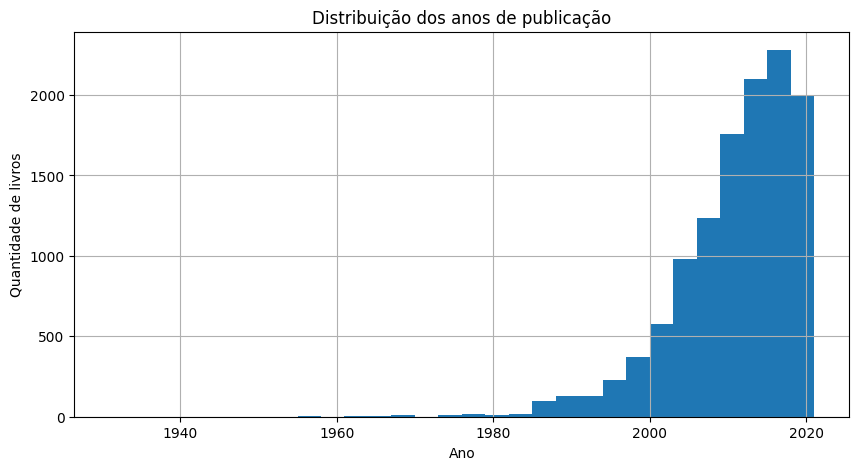

In [18]:
import matplotlib.pyplot as plt

valid_years = years[
    (years >= 1900) &
    (years <= 2021)
]

valid_years.hist(bins=30, figsize=(10, 5))

plt.title("Distribuição dos anos de publicação")
plt.xlabel("Ano")
plt.ylabel("Quantidade de livros")

plt.show()

In [19]:
import httpx

BASE_URL = "https://openlibrary.org"

params = {
    "title": "Torto Arado",
    "author": "Itamar Vieira Junior",
    "limit": 3,
}

response = httpx.get(
    f"{BASE_URL}/search.json",
    params=params,
    timeout=20
)

response.raise_for_status()

results = response.json()["docs"]

for book in results:
    print("Título:", book.get("title"))
    print("Autores:", book.get("author_name"))
    print("Ano:", book.get("first_publish_year"))
    print("Idiomas:", book.get("language"))
    print("Identificador:", book.get("key"))
    print("-" * 40)

Título: Torto Arado
Autores: ['Itamar Vieira Junior', 'Itamar Vieira Júnior']
Ano: 2019
Idiomas: ['por', 'eng']
Identificador: /works/OL24141556W
----------------------------------------


In [20]:
import time

if results:
    work_key = results[0]["key"]

    time.sleep(1.1)

    response = httpx.get(
        f"{BASE_URL}{work_key}.json",
        timeout=20
    )

    response.raise_for_status()

    work = response.json()

    description = work.get("description")

    if isinstance(description, dict):
        description = description.get("value")

    print("Título:", work.get("title"))
    print("Descrição:", description)

Título: Torto Arado
Descrição: Bibiana e Belonísia são filhas de trabalhadores de uma fazenda no Sertão da Bahia, descendentes de escravos para quem a abolição nunca passou de uma data marcada no calendário. Intrigadas com uma mala misteriosa sob a cama da avó, pagam o atrevimento de lhe pôr a mão com um acidente que mudará para sempre as suas vidas, tornando-as tão dependentes que uma será até a voz da outra.  Porém, com o avançar dos anos, a proximidade vai desfazer-se com a perspectiva que cada uma tem sobre o que as rodeia: enquanto Belonísia parece satisfeita com o trabalho na fazenda e os encantos do pai, Zeca Chapéu Grande, entre velas, incensos e ladainhas, Bibiana percebe desde cedo a injustiça da servidão que há três décadas é imposta à família e decide lutar pelo direito à terra e a emancipação dos trabalhadores. Para isso, porém, é obrigada a partir, separando-se da irmã.  Numa trama tecida de segredos antigos que têm quase sempre mulheres por protagonistas, e à sombra de d

In [21]:
# Candidatos classificados como literatura brasileira
brazilian_mask = skoob["genero"].str.contains(
    "Literatura Brasileira",
    case=False,
    na=False
)

# Comprimento das descrições
description_length = (
    skoob["descricao"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.len()
)

# Seleção exploratória
candidates = skoob[
    brazilian_mask & (description_length >= 120)
].copy()

print("Candidatos:", len(candidates))

Candidatos: 946


In [22]:
sample = candidates.sample(
    n=min(15, len(candidates)),
    random_state=42
).copy()

sample["descricao_preview"] = (
    sample["descricao"].str.slice(0, 150)
)

sample[
    ["titulo", "autor", "ano", "descricao_preview"]
]

,titulo,autor,ano,descricao_preview
6019,O fotógrafo,Cristovão Tezza,2004,Um fotógrafo de aluguel e todos os personagens...
320,Meu menino vadio,Luiz Fernando Vianna,2017,"O jornalista Luiz Fernando Vianna e seu filho,..."
11098,4 Semanas de Prazer,Julianna Costa,2014,"Depois do sucesso de 23 noites de prazer, a au..."
7616,Filho Da Noite,Antônio Calloni,2020,"Caro Leitor, você deve estar, neste momento, s..."
969,Aqueles Tempos,Edney Silvestre,2013,O escritor Edney Silvestre explora as história...
8200,Já Entendi,Gladys Mariotto,2015,Estudar é um sacrifício? Você tem a impressão ...
11965,Em Comunhão com Deus,Huberto Rohden,2008,Esta obra está dividida em duas partes Na prim...
805,O Rei de Amarelo,Robert W. Chambers,2014,'O Rei de Amarelo' é uma coletânea de contos d...
7872,O amor que sinto agora,Leila Ferreira,2018,Confidências de uma filha para a sua mãeQuatro...
10928,Silvio Santos  a biografia,Marcia Batista,2017,"Como o homem de uma família judia, levada dive..."


In [23]:
genre_counts = (
    candidates["genero"]
    .fillna("")
    .str.split("/")
    .explode()
    .str.strip()
    .str.lower()
    .value_counts()
)

genre_counts.head(20)

genero
literatura brasileira                 901
romance                               340
ficção                                277
não-ficção                            114
autoajuda                              98
religião e espiritualidade             92
infantojuvenil                         73
biografia, autobiografia, memórias     62
contos                                 43
jovem adulto                           39
história                               39
crônicas                               36
drama                                  33
poemas, poesias                        30
fantasia                               28
história do brasil                     28
suspense e mistério                    27
filosofia                              23
política                               19
humor, comédia                         18
Name: count, dtype: int64

In [24]:
# Separa e padroniza os gêneros
genre_lists = (
    candidates["genero"]
    .fillna("")
    .str.lower()
    .str.split("/")
    .apply(lambda genres: [
        genre.strip()
        for genre in genres
    ])
)

# Seleciona registros classificados como fantasia
fantasy_books = candidates[
    genre_lists.apply(lambda genres: "fantasia" in genres)
].copy()

# Seleciona registros classificados como suspense
suspense_books = candidates[
    genre_lists.apply(
        lambda genres: "suspense e mistério" in genres
    )
].copy()

print("Fantasia:", len(fantasy_books))
print("Suspense:", len(suspense_books))

Fantasia: 28
Suspense: 27


In [25]:
fantasy_books[
    ["titulo", "autor", "ano", "genero"]
].head(15)

,titulo,autor,ano,genero
24,O Livro de Líbero,Alfredo Nugent Setubal,2020,Fantasia / Ficção / Literatura Brasileira
27,O Livro De Líbero,Alfredo Nugent Setubal,2020,Fantasia / Ficção / Literatura Brasileira
167,Serpentário,Felipe Castilho,2019,Fantasia / Ficção científica / Horror / Litera...
441,Ordem Vermelha: Filhos da Degradação,Felipe Castilho,2017,Fantasia / Ficção / Literatura Brasileira
3408,Sob a Capa Vermelha,Mariana Vitória,2018,Fantasia / Ficção / Jovem adulto / Literatura ...
3453,O Livro das Princesas,Paula Pimenta,2017,Contos / Fantasia / Ficção / Infantojuvenil / ...
3476,Menina Veneno,Carina Rissi,2017,Fantasia / Literatura Brasileira
3480,Criaturas e Criadores,Raphael Draccon,2017,Contos / Fantasia / Ficção / Literatura Bras...
3692,Princesa Adormecida,Paula Pimenta,2014,Fábula / Fantasia / Literatura Brasileira / Ro...
3768,O Livro das Princesas,Paula Pimenta,2013,Contos / Fantasia / Ficção / Infantojuvenil / ...


In [26]:
suspense_books[
    ["titulo", "autor", "ano", "genero"]
].head(15)

,titulo,autor,ano,genero
805,O Rei de Amarelo,Robert W. Chambers,2014,"Literatura Estrangeira / Terror / HQ, comics, ..."
877,O Rei de Amarelo,Robert W. Chambers,2014,"Terror / Literatura Estrangeira / HQ, comics, ..."
1839,O Demônio e a Srta. Prym,Paulo Coelho,2013,  Paulo CoelhoFicção / Literatura Brasileira...
4952,O Caso Laura,André Vianco,2011,Ficção / Literatura Brasileira / Suspense e Mi...
5619,Síndrome de quimera,Max Mallmann,2007,Fantasia / Ficção / Literatura Brasileira / Ro...
5848,Sete Contos de Arrepiar,José Flávio Morais,2006,Contos / Literatura Brasileira / Suspense e Mi...
6199,O Demônio e a Srta. Prym,Paulo Coelho,2003,Ficção / Romance / Suspense e Mistério / Liter...
7671,Não Pare!,FML Pepper,2015,Suspense e Mistério / Infantojuvenil / Romance...
7672,Não Olhe!,FML Pepper,2015,Jovem adulto / Fantasia / Literatura Brasileir...
7987,Os Filhos da Tempestade,Rodrigo de Oliveira,2017,Aventura / Fantasia / Ficção / Literatura Bras...


In [27]:
import pandas as pd

# Obras selecionadas para a comparação inicial
selected_titles = [
    "O fotógrafo",
    "Meu menino vadio",
    "4 Semanas de Prazer",
    "Filho Da Noite",
    "Aqueles Tempos",
    "O amor que sinto agora",
    "Onze Minutos",
    "No Mundo da Luna",
    "Ordem Vermelha: Filhos da Degradação",
    "A Ditadura Envergonhada",
]

# Selecionar registros do Skoob
sample_books = skoob[
    skoob["titulo"].isin(selected_titles)
].copy()

# Calcular o comprimento das descrições
sample_books["description_length"] = (
    sample_books["descricao"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.len()
)

# Ordenar para inspecionar os registros mais completos
sample_books = sample_books.sort_values(
    "description_length",
    ascending=False
)

print("Registros encontrados:", len(sample_books))

display(
    sample_books[
        [
            "titulo",
            "autor",
            "ano",
            "ISBN_13",
            "description_length"
        ]
    ]
)

Registros encontrados: 11


,titulo,autor,ano,ISBN_13,description_length
895,A Ditadura Envergonhada,Elio Gaspari,2014,9788580573978,2355
441,Ordem Vermelha: Filhos da Degradação,Felipe Castilho,2017,9788551002698,1405
7616,Filho Da Noite,Antônio Calloni,2020,9788558891042,1351
9959,No Mundo da Luna,Carina Rissi,2015,9788576863021,1140
785,A Ditadura Envergonhada,Elio Gaspari,2014,9788580573978,960
320,Meu menino vadio,Luiz Fernando Vianna,2017,9788551000946,911
11098,4 Semanas de Prazer,Julianna Costa,2014,9788579307263,799
7872,O amor que sinto agora,Leila Ferreira,2018,9788542211245,794
6216,Onze Minutos,Paulo Coelho,2003,9788532515360,397
6019,O fotógrafo,Cristovão Tezza,2004,9788532517951,334


In [28]:
import httpx
import time

test_books = [
    ("O fotógrafo", "Cristovão Tezza"),
    ("No Mundo da Luna", "Carina Rissi"),
    ("Ordem Vermelha: Filhos da Degradação", "Felipe Castilho"),
]

BASE_URL = "https://openlibrary.org"

results = []

for title, author in test_books:

    params = {
        "title": title,
        "author": author,
        "limit": 3
    }

    response = httpx.get(
        f"{BASE_URL}/search.json",
        params=params,
        timeout=20
    )

    response.raise_for_status()

    data = response.json()

    print(f"\nBuscando: {title}")

    for book in data.get("docs", []):
        print("Título:", book.get("title"))
        print("Autor:", book.get("author_name"))
        print("ID:", book.get("key"))
        print("Ano:", book.get("first_publish_year"))
        print("-" * 30)

        results.append({
            "searched_title": title,
            "title": book.get("title"),
            "authors": book.get("author_name"),
            "work_id": book.get("key"),
            "year": book.get("first_publish_year"),
        })

    time.sleep(1.1)


Buscando: O fotógrafo
Título: O fotógrafo
Autor: ['Cristovão Tezza']
ID: /works/OL2305985W
Ano: 2004
------------------------------

Buscando: No Mundo da Luna
Título: No mundo da Luna
Autor: ['Carina Rissi']
ID: /works/OL45976431W
Ano: 2017
------------------------------

Buscando: Ordem Vermelha: Filhos da Degradação
Título: Ordem Vermelha. Filhos da Degradacao - Volume 1
Autor: ['Castilho Felipe']
ID: /works/OL25629084W
Ano: 2017
------------------------------


In [29]:
import httpx
import time

BASE_URL = "https://openlibrary.org"

work_details = []

for book in results:
    work_id = book["work_id"]

    time.sleep(1.1)

    response = httpx.get(
        f"{BASE_URL}{work_id}.json",
        timeout=20
    )

    response.raise_for_status()
    data = response.json()

    # A descrição pode ser texto ou dicionário
    description = data.get("description", "")

    if isinstance(description, dict):
        description = description.get("value", "")

    description = description or ""

    subjects = data.get("subjects", [])

    work_details.append({
        "title": book["title"],
        "work_id": work_id,
        "description": description,
        "description_length": len(description),
        "subjects": subjects,
        "source_url": f"{BASE_URL}{work_id}"
    })

    print(f"\nLivro: {book['title']}")
    print("Descrição disponível:", bool(description))
    print("Caracteres:", len(description))
    print("Descrição:", description[:500])
    print("Assuntos:", subjects[:5])
    print("-" * 60)


Livro: O fotógrafo
Descrição disponível: False
Caracteres: 0
Descrição: 
Assuntos: ['Novels']
------------------------------------------------------------

Livro: No mundo da Luna
Descrição disponível: False
Caracteres: 0
Descrição: 
Assuntos: []
------------------------------------------------------------

Livro: Ordem Vermelha. Filhos da Degradacao - Volume 1
Descrição disponível: False
Caracteres: 0
Descrição: 
Assuntos: []
------------------------------------------------------------


In [30]:
target_titles = [
    "O fotógrafo",
    "No Mundo da Luna",
    "Ordem Vermelha: Filhos da Degradação",
]

description_audit = skoob[
    skoob["titulo"].isin(target_titles)
].copy()

# Quantidade de palavras em cada descrição
description_audit["word_count"] = (
    description_audit["descricao"]
    .fillna("")
    .str.split()
    .str.len()
)

# Prévia para inspeção manual
description_audit["description_preview"] = (
    description_audit["descricao"]
    .fillna("")
    .str.slice(0, 300)
)

display(
    description_audit[
        [
            "titulo",
            "autor",
            "word_count",
            "description_preview"
        ]
    ]
)

,titulo,autor,word_count,description_preview
441,Ordem Vermelha: Filhos da Degradação,Felipe Castilho,232,Você destruiria seu mundo em nome da verdade?A...
6019,O fotógrafo,Cristovão Tezza,54,Um fotógrafo de aluguel e todos os personagens...
9959,No Mundo da Luna,Carina Rissi,199,A vida de Luna está uma bagunça! O namorado a ...


In [31]:
for _, book in description_audit.iterrows():
    print("=" * 70)
    print(f"Livro: {book['titulo']}")
    print(f"Autor: {book['autor']}")
    print(f"Palavras: {book['word_count']}")
    print("-" * 70)

    print(book["descricao"])
    print()

Livro: Ordem Vermelha: Filhos da Degradação
Autor: Felipe Castilho
Palavras: 232
----------------------------------------------------------------------
Você destruiria seu mundo em nome da verdade?A última região habitada do mundo, Untherak, é povoada por humanos, anões e gigantes, sinfos, kaorshs e gnolls Nela, a deusa Una reina soberana, lembrando a todos a missão maior de suas vidas: servir a Ela sem questionamentos No entanto, um pequeno grupo de rebeldes, liderado por uma figura misteriosa, está disposto a tudo para tirá-la do tronoCom essa fagulha de esperança, mais indivíduos se unem à causa e mostram a Una que seus dias talvez estejam contados Um grupo instável e heterogêneo que precisará resolver suas diferenças a fim não só de desvendar os segredos de Untherak, mas também enfrentar seu mais terrível guardião, o General Proghon, e preparar-se para a possibilidade de um futuro totalmente desconhecido Se uma deusa cai, o que vem depois?Ordem Vermelha: Filhos da Degradação é o pr

In [32]:
from bookmatch.data.cleaning import normalize_description

selected = [
    "Ordem Vermelha: Filhos da Degradação",
    "O fotógrafo",
    "No Mundo da Luna",
]

catalog_candidates = skoob[
    skoob["titulo"].isin(selected)
].copy()

# Aplicar nossa função de limpeza
catalog_candidates["description_clean"] = (
    catalog_candidates["descricao"]
    .apply(normalize_description)
)

# Informações de verificação
catalog_candidates["author_verified"] = False
catalog_candidates["author_source_url"] = pd.NA

catalog_candidates["description_source_url"] = pd.NA
catalog_candidates["description_usage_status"] = "unverified"

catalog_candidates["review_status"] = "pending"

display(
    catalog_candidates[
        [
            "titulo",
            "autor",
            "author_verified",
            "author_source_url",
            "description_usage_status",
            "review_status"
        ]
    ]
)

,titulo,autor,author_verified,author_source_url,description_usage_status,review_status
441,Ordem Vermelha: Filhos da Degradação,Felipe Castilho,False,<NA>,unverified,pending
6019,O fotógrafo,Cristovão Tezza,False,<NA>,unverified,pending
9959,No Mundo da Luna,Carina Rissi,False,<NA>,unverified,pending


In [33]:
verified_sources = {
    "Ordem Vermelha: Filhos da Degradação": {
        "author_url": "https://www.felipecastilho.net.br/sobre",
        "book_url": "https://loja.intrinseca.com.br/ordem-vermelha-filhos-da-degradac-o-vol-1/",
    },
    "O fotógrafo": {
        "author_url": "https://www.cristovaotezza.com.br/p_biografia.htm",
        "book_url": "https://www.record.com.br/products/o-fotografo-1",
    },
    "No Mundo da Luna": {
        "author_url": "https://carinarissi.com.br/sobre-a-autora",
        "book_url": "https://www.record.com.br/products/no-mundo-da-luna/",
    },
}

catalog_candidates["book_source_url"] = pd.NA

for title, sources in verified_sources.items():
    mask = catalog_candidates["titulo"] == title

    catalog_candidates.loc[mask, "author_verified"] = True
    catalog_candidates.loc[mask, "author_source_url"] = sources["author_url"]
    catalog_candidates.loc[mask, "book_source_url"] = sources["book_url"]
    catalog_candidates.loc[mask, "review_status"] = "work_verified"

display(
    catalog_candidates[
        [
            "titulo",
            "autor",
            "author_verified",
            "book_source_url",
            "description_usage_status",
            "review_status",
        ]
    ]
)

,titulo,autor,author_verified,book_source_url,description_usage_status,review_status
441,Ordem Vermelha: Filhos da Degradação,Felipe Castilho,True,https://loja.intrinseca.com.br/ordem-vermelha-...,unverified,work_verified
6019,O fotógrafo,Cristovão Tezza,True,https://www.record.com.br/products/o-fotografo-1,unverified,work_verified
9959,No Mundo da Luna,Carina Rissi,True,https://www.record.com.br/products/no-mundo-da...,unverified,work_verified


In [34]:
import httpx
import pandas as pd

API_URL = "https://pt.wikipedia.org/w/api.php"

# Substitua pelo endereço do seu repositório público
PROJECT_URL = "https://github.com/SEU-USUARIO/bookmatch-ai"

headers = {
    "User-Agent": f"BookMatchAI/0.1 ({PROJECT_URL})"
}

titles = [
    "Dom Casmurro",
    "A Hora da Estrela",
    "Ordem Vermelha",
]

params = {
    "action": "query",
    "prop": "extracts",
    "exintro": 1,
    "explaintext": 1,
    "titles": "|".join(titles),
    "format": "json",
    "formatversion": 2,
}

response = httpx.get(
    API_URL,
    params=params,
    headers=headers,
    timeout=20,
)

response.raise_for_status()

pages = response.json()["query"]["pages"]

for page in pages:
    description = page.get("extract", "")

    print("\nLivro:", page["title"])
    print("Encontrado:", not page.get("missing", False))
    print("Caracteres:", len(description))
    print("Texto:", description[:400])
    print("-" * 60)


Livro: Ordem Vermelha
Encontrado: False
Caracteres: 0
Texto: 
------------------------------------------------------------

Livro: Dom Casmurro
Encontrado: True
Caracteres: 2167
Texto: Dom Casmurro é um romance escrito por Machado de Assis, publicado em 1899 pela Livraria Garnier. Escrito para publicação em livro, o que ocorreu em 1900 – embora com data do ano anterior, ao contrário de Memórias Póstumas de Brás Cubas (1881) e Quincas Borba (1891), escritos antes em folhetins –, é considerado pela crítica o terceiro romance da "Trilogia Realista" de Machado de Assis, ao lado dess
------------------------------------------------------------

Livro: A Hora da Estrela
Encontrado: True
Caracteres: 248
Texto: A Hora da Estrela é um romance literário da escritora brasileira Clarice Lispector.
O romance narra a história da datilógrafa alagoana, Macabéa, que migra para o Rio de Janeiro, tendo sua rotina narrada por um escritor fictício chamado Rodrigo S.M.
-------------------------------------

In [35]:
from pathlib import Path
from urllib.parse import quote

audit = []

for page in pages:
    title = page["title"]
    description = page.get("extract", "")
    found = not page.get("missing", False)

    audit.append({
        "title": title,
        "found": found,
        "description_length": len(description),
        "source_name": "Wikipedia",
        "source_url": (
            "https://pt.wikipedia.org/wiki/"
            + quote(title.replace(" ", "_"))
            if found else None
        ),
        "review_status": "pending" if found else "not_found",
    })

wiki_audit = pd.DataFrame(audit)

output_path = Path("../data/interim")
output_path.mkdir(parents=True, exist_ok=True)

wiki_audit.to_csv(
    output_path / "wikipedia_audit.csv",
    index=False
)

wiki_audit

,title,found,description_length,source_name,source_url,review_status
0,Ordem Vermelha,False,0,Wikipedia,None,not_found
1,Dom Casmurro,True,2167,Wikipedia,https://pt.wikipedia.org/wiki/Dom_Casmurro,pending
2,A Hora da Estrela,True,248,Wikipedia,https://pt.wikipedia.org/wiki/A_Hora_da_Estrela,pending


In [36]:
from pathlib import Path
from urllib.parse import quote

import pandas as pd

from bookmatch.data.cleaning import normalize_description

records = []

for page in pages:
    if page.get("missing", False):
        continue

    description = page.get("extract", "")

    if not description.strip():
        continue

    records.append({
        "source_id": f"wikipedia:{page['pageid']}",
        "title": page["title"],
        "description_raw": description,
        "description_clean": normalize_description(description),
        "language": "pt",
        "source_name": "Wikipedia",
        "source_url": (
            "https://pt.wikipedia.org/wiki/"
            + quote(page["title"].replace(" ", "_"))
        ),
        "review_status": "pending",
    })

wiki_books = pd.DataFrame(records)

output_path = Path("../data/interim")
output_path.mkdir(parents=True, exist_ok=True)

wiki_books.to_csv(
    output_path / "wikipedia_candidates.csv",
    index=False
)

print("Registros salvos:", len(wiki_books))

wiki_books[["title", "source_name", "review_status"]]

Registros salvos: 2


,title,source_name,review_status
0,Dom Casmurro,Wikipedia,pending
1,A Hora da Estrela,Wikipedia,pending


In [37]:
author_mapping = {
    "Dom Casmurro": "Machado de Assis",
    "A Hora da Estrela": "Clarice Lispector",
}

wiki_books["authors"] = wiki_books["title"].map(author_mapping)

wiki_books["author_verified"] = False
wiki_books["author_source_url"] = pd.NA

wiki_books["description_usage_status"] = "pending"

wiki_books[
    [
        "title",
        "authors",
        "author_verified",
        "description_usage_status",
        "review_status",
    ]
]

,title,authors,author_verified,description_usage_status,review_status
0,Dom Casmurro,Machado de Assis,False,pending,pending
1,A Hora da Estrela,Clarice Lispector,False,pending,pending


In [38]:
from bookmatch.data.catalog import validate_candidates

validated = validate_candidates(wiki_books)

display(
    validated[
        [
            "title",
            "metadata_complete",
            "author_valid",
            "usage_valid",
            "is_valid",
        ]
    ]
)

print("Registros válidos:", validated["is_valid"].sum())

,title,metadata_complete,author_valid,usage_valid,is_valid
0,Dom Casmurro,True,False,False,False
1,A Hora da Estrela,True,False,False,False


Registros válidos: 0


In [39]:
author_evidence = {
    "Dom Casmurro": {
        "author": "Machado de Assis",
        "url": "https://www2.academia.org.br/academicos/machado-de-assis/biografia",
    },
    "A Hora da Estrela": {
        "author": "Clarice Lispector",
        "url": "https://www.pucrs.br/cultura/projetos/cem-anos-de-clarice/",
    },
}

for title, evidence in author_evidence.items():
    mask = wiki_books["title"] == title

    wiki_books.loc[mask, "authors"] = evidence["author"]
    wiki_books.loc[mask, "author_verified"] = True
    wiki_books.loc[mask, "author_source_url"] = evidence["url"]

In [40]:
wiki_books["description_license"] = "CC BY-SA 4.0"

wiki_books["description_license_url"] = (
    "https://creativecommons.org/licenses/by-sa/4.0/"
)

wiki_books["description_usage_status"] = "pending"

In [41]:
validated = validate_candidates(wiki_books)

display(
    validated[
        [
            "title",
            "author_valid",
            "usage_valid",
            "is_valid",
        ]
    ]
)

,title,author_valid,usage_valid,is_valid
0,Dom Casmurro,True,False,False
1,A Hora da Estrela,True,False,False


In [42]:
from bookmatch.data.cleaning import normalize_description

mask = (
    skoob["genero"]
    .astype("string")
    .str.contains(
        "Literatura Brasileira",
        case=False,
        regex=False,
        na=False,
    )
    &
    skoob["descricao"]
    .astype("string")
    .str.len()
    .ge(120)
    .fillna(False)
)

candidates = skoob.loc[
    mask,
    ["titulo", "autor", "descricao", "genero", "ano", "ISBN_13"]
].copy()

candidates = candidates.rename(columns={
    "titulo": "title",
    "autor": "authors",
    "descricao": "description_raw",
    "genero": "genres",
    "ano": "publication_year",
})

candidates["description_clean"] = (
    candidates["description_raw"]
    .apply(normalize_description)
)

candidates["author_verified"] = False
candidates["description_usage_status"] = "unverified"
candidates["review_status"] = "pending"

print(f"Candidatos encontrados: {len(candidates)}")

Candidatos encontrados: 946


In [43]:
from bookmatch.retrieval.bm25 import BM25Retriever

# Selecionar e preparar os documentos
documents = (
    candidates[
        ["title", "authors", "description_clean"]
    ]
    .dropna()
    .drop_duplicates(subset=["title", "authors"])
    .to_dict("records")
)

# Construir o recuperador
retriever = BM25Retriever(documents)

# Consulta
query = "fantasia medieval com magia e rebeliões"

results = retriever.search(query, top_k=5)

for i, book in enumerate(results, start=1):
    print(f"{i}. {book['title']}")
    print(f"   Autor: {book['authors']}")
    print(f"   BM25 Score: {book['score']:.4f}")
    print()

1. Ordem Vermelha: Filhos da Degradação
   Autor: Felipe Castilho
   BM25 Score: 15.5335

2. TazerCraft
   Autor: Gustavo Magnani
   BM25 Score: 13.8858

3. Brigada dos Amaldiçoados
   Autor: Albert Vaz
   BM25 Score: 11.5558

4. A Batalha do Apocalipse
   Autor: Eduardo Spohr
   BM25 Score: 11.5502

5. No Mundo da Luna
   Autor: Carina Rissi
   BM25 Score: 11.4999



In [44]:
from bookmatch.retrieval.bm25 import tokenize

query_tokens = set(tokenize(query))

for rank, book in enumerate(results, start=1):
    document_text = (
        book["title"] + " " + book["description_clean"]
    )

    document_tokens = set(tokenize(document_text))

    matched_terms = sorted(
        query_tokens.intersection(document_tokens)
    )

    print(f"\n{rank}. {book['title']}")
    print(f"Autor: {book['authors']}")
    print(f"Score: {book['score']:.4f}")
    print(f"Termos encontrados: {matched_terms}")


1. Ordem Vermelha: Filhos da Degradação
Autor: Felipe Castilho
Score: 15.5335
Termos encontrados: ['com', 'e', 'fantasia', 'medieval']

2. TazerCraft
Autor: Gustavo Magnani
Score: 13.8858
Termos encontrados: ['com', 'e', 'fantasia', 'magia']

3. Brigada dos Amaldiçoados
Autor: Albert Vaz
Score: 11.5558
Termos encontrados: ['com', 'e', 'magia']

4. A Batalha do Apocalipse
Autor: Eduardo Spohr
Score: 11.5502
Termos encontrados: ['e', 'magia', 'medieval']

5. No Mundo da Luna
Autor: Carina Rissi
Score: 11.4999
Termos encontrados: ['com', 'e', 'magia']


In [45]:
from pathlib import Path

output_path = Path("../data/interim")
output_path.mkdir(parents=True, exist_ok=True)

candidates.to_csv(
    output_path / "skoob_candidates.csv",
    index=False
)

print(f"Registros salvos: {len(candidates)}")

Registros salvos: 946
